## Loading KDEF dataset

This notebook has the necessary code to load and split your KDEF dataset. The training and test splits are already predefined.

In [ ]:
#All imports for this notebook

from pathlib import Path
import pickle
import sys
import matplotlib.pyplot as plt
import numpy as np
import math
import pandas as pd

from sklearn.model_selection import train_test_split

#set up and validate data directory
ROOT = Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

DATA = ROOT / "data" / "kdef"
SPLIT = ROOT / "auxFiles" / "kdef_subject_split.pkl"
PREPROCESSED_DATA = DATA / "kdef_preprocessed.pkl"
print(DATA)
print(DATA.exists())   # should print True

from scripts.utils_display import show_random_subject_emotions
from scripts.preprocess import preprocess_kdef_image

/home/thesuacar/Desktop/DALM/ml-emotionalrecognition/data/kdef
True


In [27]:
EMOTIONS = {
    "AF": "afraid",
    "AN": "angry",
    "DI": "disgust",
    "HA": "happy",
    "NE": "neutral",
    "SA": "sad",
    "SU": "surprise",
    
}

POSES = {
    "FL": "full_left",
    "HL": "half_left",
    "S":  "straight",
    "HR": "half_right",
    "FR": "full_right",
}

In [28]:
records = []

for img_path in DATA.rglob("*.JPG"):
    stem = img_path.stem
    acquisition = stem[0]   # A or B
    subject = stem[1:4]     # F01, M12, ...
    found = False

    for emotion_code in EMOTIONS:

        if stem[4:].startswith(emotion_code):

            pose_code = stem[4+len(emotion_code):]

            if pose_code not in POSES:
                continue

            records.append({
                "path": str(img_path),
                "acquisition": acquisition,
                "subject": subject,
                "emotion": EMOTIONS[emotion_code],
                "pose": POSES[pose_code],
            })


            found = True
            break

    if not found:
        print("Skipping:", stem)


Skipping: AM31H
Skipping: AF31V


In [29]:
df = pd.DataFrame(records)

print(df["emotion"].value_counts())
print()
print(df["subject"].nunique())
print(sorted(df.emotion.unique()))
print(df.pose.value_counts())


emotion
neutral     700
angry       700
afraid      700
happy       700
disgust     700
sad         699
surprise    699
Name: count, dtype: int64

70
['afraid', 'angry', 'disgust', 'happy', 'neutral', 'sad', 'surprise']
pose
full_left     980
straight      980
full_right    980
half_right    979
half_left     979
Name: count, dtype: int64


In [30]:
print(df)

                                                   path acquisition subject  \
0     /home/thesuacar/Desktop/DALM/ml-emotionalrecog...           A     M03   
1     /home/thesuacar/Desktop/DALM/ml-emotionalrecog...           A     M03   
2     /home/thesuacar/Desktop/DALM/ml-emotionalrecog...           A     M03   
3     /home/thesuacar/Desktop/DALM/ml-emotionalrecog...           A     M03   
4     /home/thesuacar/Desktop/DALM/ml-emotionalrecog...           A     M03   
...                                                 ...         ...     ...   
4893  /home/thesuacar/Desktop/DALM/ml-emotionalrecog...           B     M20   
4894  /home/thesuacar/Desktop/DALM/ml-emotionalrecog...           B     M20   
4895  /home/thesuacar/Desktop/DALM/ml-emotionalrecog...           B     M20   
4896  /home/thesuacar/Desktop/DALM/ml-emotionalrecog...           B     M20   
4897  /home/thesuacar/Desktop/DALM/ml-emotionalrecog...           B     M20   

      emotion        pose  
0     neutral   full_le

In [31]:
"""
#This code is only used for setting up the split. Output file given to the students
#no longer needed afterwards

subjects = df["subject"].unique()

train_subjects, test_subjects = train_test_split(
    subjects,
    test_size=0.2,
    random_state=42,
)

train_df = df[df["subject"].isin(train_subjects)]
test_df = df[df["subject"].isin(test_subjects)]

split_data = {
    "train_subjects": train_subjects,
    "test_subjects": test_subjects,
}

with open("auxFiles/kdef_subject_split.pkl", "wb") as f:
    pickle.dump(split_data, f)
"""


'\n#This code is only used for setting up the split. Output file given to the students\n#no longer needed afterwards\n\nsubjects = df["subject"].unique()\n\ntrain_subjects, test_subjects = train_test_split(\n    subjects,\n    test_size=0.2,\n    random_state=42,\n)\n\ntrain_df = df[df["subject"].isin(train_subjects)]\ntest_df = df[df["subject"].isin(test_subjects)]\n\nsplit_data = {\n    "train_subjects": train_subjects,\n    "test_subjects": test_subjects,\n}\n\nwith open("auxFiles/kdef_subject_split.pkl", "wb") as f:\n    pickle.dump(split_data, f)\n'

In [32]:
with open(SPLIT, "rb") as f:
    split_data = pickle.load(f)

train_subjects = split_data["train_subjects"]
test_subjects = split_data["test_subjects"]

print(f"Train subjects: {len(train_subjects)}")
print(f"Test subjects : {len(test_subjects)}")


# Splitting the datasets between front facing images and for the train/test datasets
train_df = df[
    (df["subject"].isin(train_subjects))
    & (df["pose"] == "straight")
]

test_df = df[
    (df["subject"].isin(test_subjects))
    & (df["pose"] == "straight")
]

Train subjects: 56
Test subjects : 14


In [33]:
print("Train images:", len(train_df))
print("Test images :", len(test_df))

Train images: 784
Test images : 196


Subject: M12


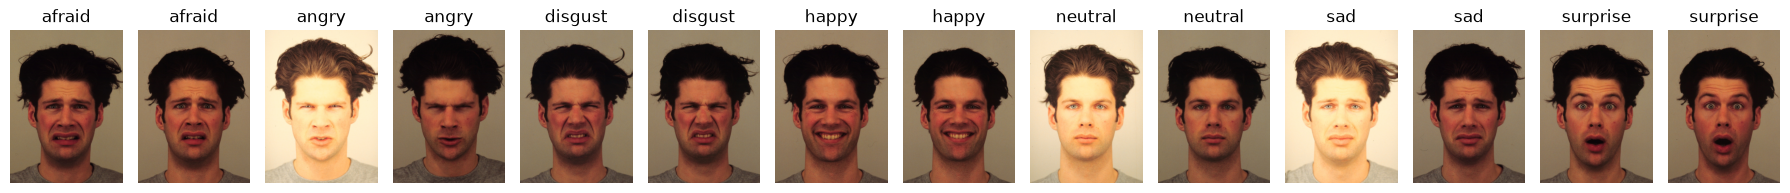

Subject: F01


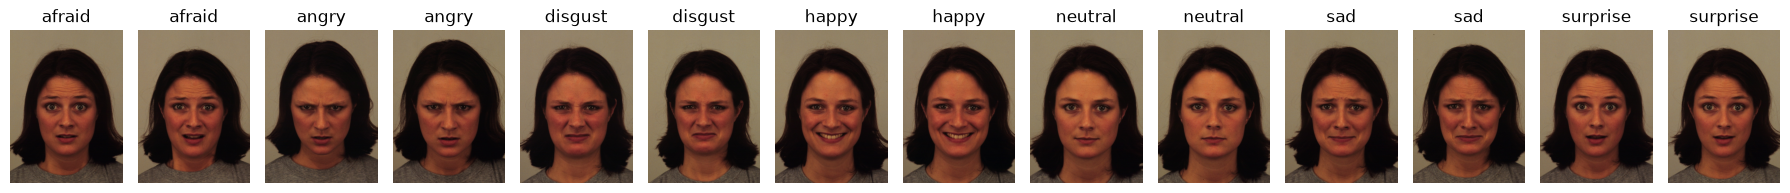

In [34]:
show_random_subject_emotions(train_df)
show_random_subject_emotions(test_df)

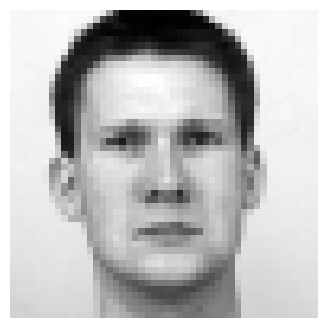

In [35]:
img = preprocess_kdef_image(
train_df.iloc[0]["path"]
)

def show_preprocessing(image_path):
    processed = preprocess_kdef_image(image_path)

    plt.figure(figsize=(4,4))
    plt.imshow(processed, cmap="gray")
    plt.axis("off")
    plt.show()

show_preprocessing(
    test_df.iloc[56]["path"]
)

The next part of the code iterates over all the images in the dataset and stores them in np arrays for easy processing

In [36]:
X_train = []
y_train = []

for _, row in train_df.iterrows():

    try:
        img = preprocess_kdef_image(
            row["path"]
        )

        X_train.append(img)
        y_train.append(row["emotion"])

    except Exception as e:
        print(e)



X_train = np.array(X_train)
y_train = np.array(y_train)

X_test = []
y_test = []

for _, row in test_df.iterrows():

    try:
        img = preprocess_kdef_image(
            row["path"]
        )

        X_test.append(img)
        y_test.append(row["emotion"])

    except Exception as e:
        print(e)

X_test = np.array(X_test)
y_test = np.array(y_test)


#Storing the preprocessed KDEF dataset
data = {
    "X_train": X_train,
    "y_train": y_train,
    "X_test": X_test,
    "y_test": y_test,
}

with open(PREPROCESSED_DATA, "wb") as f:
    pickle.dump(data, f)

print("Saved.")

Saved.


Now let's see a few of our preprocessed images. Note that both sessions A and B now are stored. The data array contains first all the A session images, and afterwards all the B session images

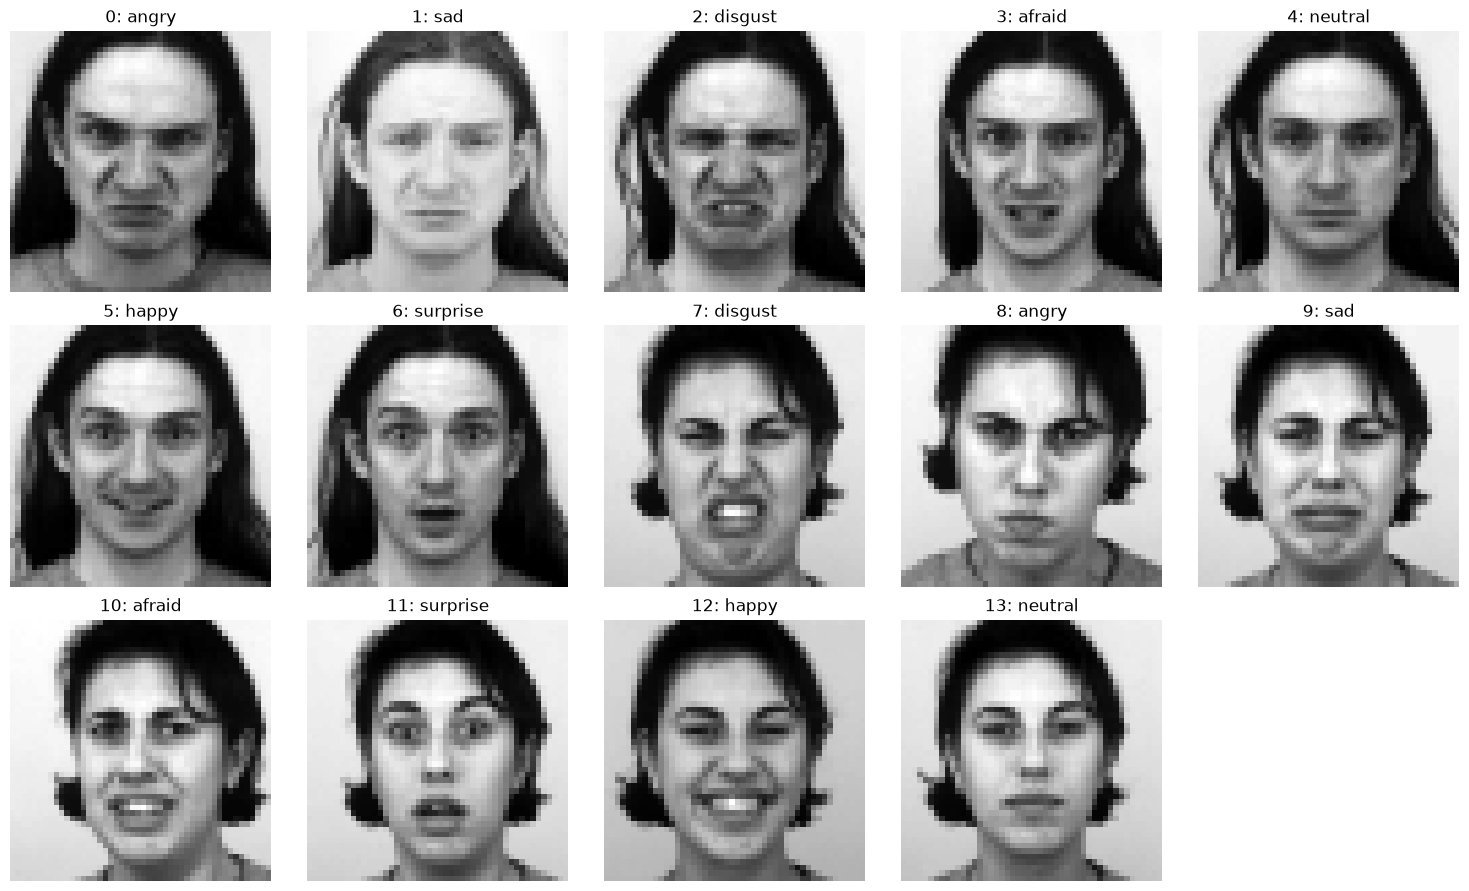

In [37]:
def show_samples(X, y, start_idx, end_idx):
    """
    Display images from start_idx to end_idx (exclusive)
    together with their emotion labels.
    """

    n = end_idx - start_idx
    cols = 5
    rows = math.ceil(n / cols)

    plt.figure(figsize=(3 * cols, 3 * rows))

    for i, idx in enumerate(range(start_idx, end_idx)):
        plt.subplot(rows, cols, i + 1)

        img = X[idx]

        # grayscale or RGB
        if img.ndim == 2:
            plt.imshow(img, cmap="gray")
        else:
            plt.imshow(img)

        plt.title(f"{idx}: {y[idx]}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


# This is an example of the images of the session A
show_samples(X_train, y_train, start_idx=0, end_idx=14)

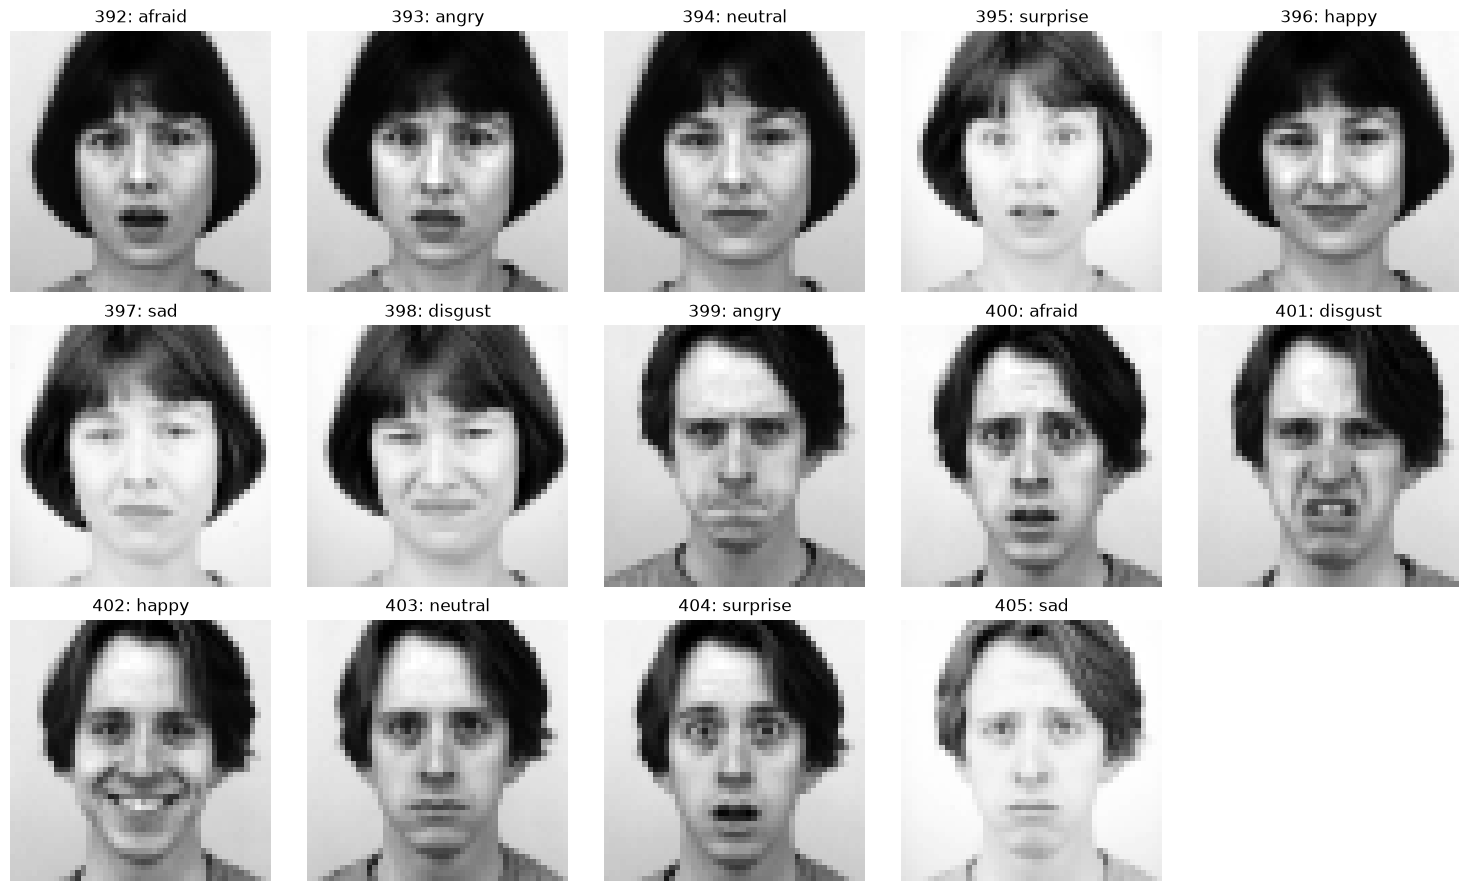

In [38]:
# This is an example of the images of the session B
show_samples(X_train, y_train, start_idx=392, end_idx=406)